# 01 - Exploratory data analysis

**Goal of this notebook:** understand the raw data before building any model.
We check that train and test files are consistent, look at missing values, study the
four targets (`M`, `MM`, `Combo`, `DCombo`) and detect data-quality problems that the
cleaning step (notebook 02) will have to solve.

Every decision taken later in the project is justified by a finding in this notebook.

## 1. Setup and data loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from miopia.config import FIGURES, RANDOM_STATE
from miopia.data import load_raw

# Display options: show all columns and round floats for readability
pd.set_option("display.max_columns", 60)
pd.set_option("display.precision", 2)
sns.set_theme(style="whitegrid", context="notebook")
FIGURES.mkdir(parents=True, exist_ok=True)

X_train, Y_train, X_test = load_raw()
print("X_train:", X_train.shape, "| Y_train:", Y_train.shape, "| X_test:", X_test.shape)

X_train: (132, 49) | Y_train: (132, 4) | X_test: (24, 49)


In [2]:
# First rows of the features and the labels
display(X_train.head())
display(Y_train.head())

,fecha,edad,sexo,origen antepasados (españa),origen antepasados (extranjeros),hº deporte sem,hº naturaleza sem,hº ocio exteriores sem,horas exterior sem,hº estudiar sem,hº ocio inter sem,hº act.cerca sem,horas interior sem,Ratio Cerca/Lejos,Exterior Mucho,Interior Mcho,fototipo,Grupo fot,familiar miope,Familiar miope num.,Familiar MM SI/NO,familiar miope magno,pat. Ret. Miop magna,fumador,toma sol,protege sol,disp.elec.antes dormir,LA OD,LA OS,LA Media,Querato OD,Querato OD Eje2,Querato OS,Querato OS Eje 2,OD-Total,OD-Media,OD-DS,OS-Total,OS-Media,OS-DS,CUVAF-Total,CUVAF-Media,CUVAF-DS,Promedio Nasal,DE Nasal,Suma Nasal,Promedio Temporal,DE Temporal,Suma Temporal
0,2/11/20,22,Mujer,Asturias,NaN,0.0,0.0,4.0,4.0,40,6,NaN,46.0,11.50,NO,NO,Fototipo 3,E,"Madre, Hermanos",1.0,Si,Hermanos,No,NO,SI,SI,A veces,24.92,25.40,25.16,45.18,46.36,45.12,46.55,1.92,0.96,1.20,0.34,0.17,0.24,2.26,0.56,0.84,0.91,1.28,1.81,0.22,0.16,0.45
1,2/17/20,23,Mujer,Navarra,NaN,5.0,2.0,2.0,9.0,20,30,NaN,50.0,5.56,NO,NO,Fototipo 4,E,No,0.0,No,No,No,NO,SI,SI,A veces,23.36,23.34,23.35,44.12,44.53,44.35,44.82,3.73,1.86,1.98,4.30,2.15,2.59,8.03,2.01,1.89,3.62,0.50,7.24,0.39,0.10,0.79
2,3/10/20,22,Mujer,Bizkaia,NaN,2.0,3.0,8.0,13.0,30,15,NaN,45.0,3.46,NO,NO,Fototipo 4,NaN,"Padre, Madre",2.0,No,No,No,NO,SI,SI,Siempre,22.40,22.45,22.43,45.12,46.17,45.18,45.92,5.25,2.62,0.50,7.46,3.73,0.43,12.71,3.18,0.74,3.15,1.25,6.30,3.20,0.31,6.41
3,2/26/20,22,Mujer,"Navarra, Extremadura, Cataluña, Aragón",España,0.0,2.0,13.0,15.0,54,12,NaN,66.0,4.40,NO,NO,E,E,No,0.0,No,No,No lo se,NO,SI,SI,Siempre,24.34,24.11,24.23,42.99,43.49,43.27,44.06,0.42,0.21,0.30,3.13,1.56,0.63,3.55,0.89,0.88,1.00,1.42,2.01,0.77,0.49,1.54
4,2/19/20,23,Mujer,Toledo,NaN,3.0,0.0,0.0,3.0,56,15,NaN,71.0,23.67,SI,NO,Fototipo 3,E,No,0.0,No,No,No,SI,NO,NO,Siempre,22.47,22.51,22.49,44.64,45.61,44.41,45.67,0.00,0.00,0.00,1.79,0.90,1.27,1.79,0.45,0.90,0.90,1.27,1.79,0.00,0.00,0.00


,M,MM,Combo,DCombo
0,SI,SI,MM,MM
1,SI,NO,M,M1
2,NO,NO,C,C
3,NO,NO,C,C
4,NO,NO,C,C


## 2. Are train and test consistent?

Both feature files must have the same columns, in the same order and with the same types,
otherwise a model trained on one cannot be applied to the other.

In [3]:
# Same column names and order?
print("Same columns and order:", list(X_train.columns) == list(X_test.columns))

# Columns whose dtype differs between train and test
dtype_diff = pd.DataFrame({"train": X_train.dtypes, "test": X_test.dtypes})
dtype_diff[dtype_diff["train"] != dtype_diff["test"]]

Same columns and order: True


,train,test
hº ocio exteriores sem,float64,int64
hº ocio inter sem,int64,float64
Familiar miope num.,float64,int64


The column names match. Three numeric columns have a different dtype (`int64` in one file,
`float64` in the other). This is only a storage format issue: pandas reads a column as
float when it contains a decimal value or a missing value (`NaN` only exists for floats).
We cast every numeric column to `float` in both files so they have exactly the same schema.

In [4]:
num_cols = X_train.select_dtypes(include="number").columns
X_train[num_cols] = X_train[num_cols].astype(float)
X_test[num_cols] = X_test[num_cols].astype(float)

print("All dtypes match now:", (X_train.dtypes == X_test.dtypes).all())
print(f"{len(num_cols)} numeric columns, {X_train.shape[1] - len(num_cols)} text columns")

All dtypes match now: True
33 numeric columns, 16 text columns


## 3. Missing values

In [5]:
# Percentage of missing values per column, in train and test
missing = pd.DataFrame({
    "train_%": X_train.isna().mean() * 100,
    "test_%": X_test.isna().mean() * 100,
}).round(1)
missing = missing[missing.sum(axis=1) > 0].sort_values("train_%", ascending=False)
missing

,train_%,test_%
hº act.cerca sem,100.0,100.0
origen antepasados (extranjeros),74.2,75.0
Grupo fot,18.2,16.7
fototipo,15.9,16.7
Familiar miope num.,3.0,0.0
origen antepasados (españa),1.5,4.2
hº ocio exteriores sem,1.5,0.0
pat. Ret. Miop magna,1.5,4.2
horas interior sem,0.8,0.0
familiar miope,0.8,0.0


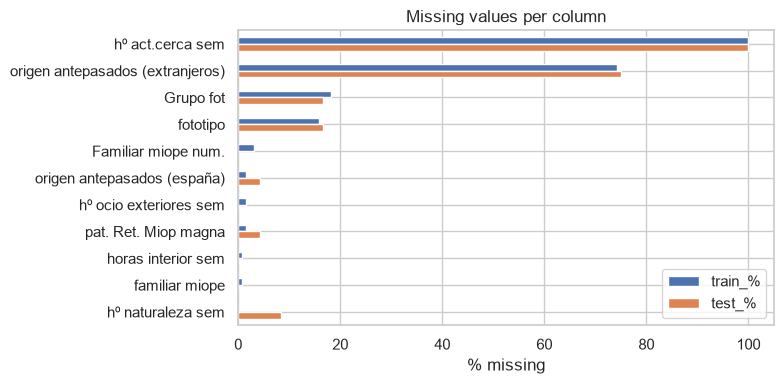

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
missing.plot.barh(ax=ax)
ax.set_xlabel("% missing")
ax.set_title("Missing values per column")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(FIGURES / "01_missing_values.png", dpi=150)
plt.show()

- `hº act.cerca sem` is **100 % empty** in both files: it carries no information and will be dropped.
- `origen antepasados (extranjeros)` is ~75 % empty, but here a blank most likely means
  "no foreign ancestors", not "unknown".
- `fototipo` / `Grupo fot` have ~17 % missing values and will need imputation.
- The rest have only a few missing values (≤ 8 %).

## 4. Targets

The professor provides four targets. Note two differences with the brief:
labels are written `SI`/`NO` (not `YES`/`NO`), and `Combo`/`DCombo` are **multi-class**
problems (one label per student), not multi-label.

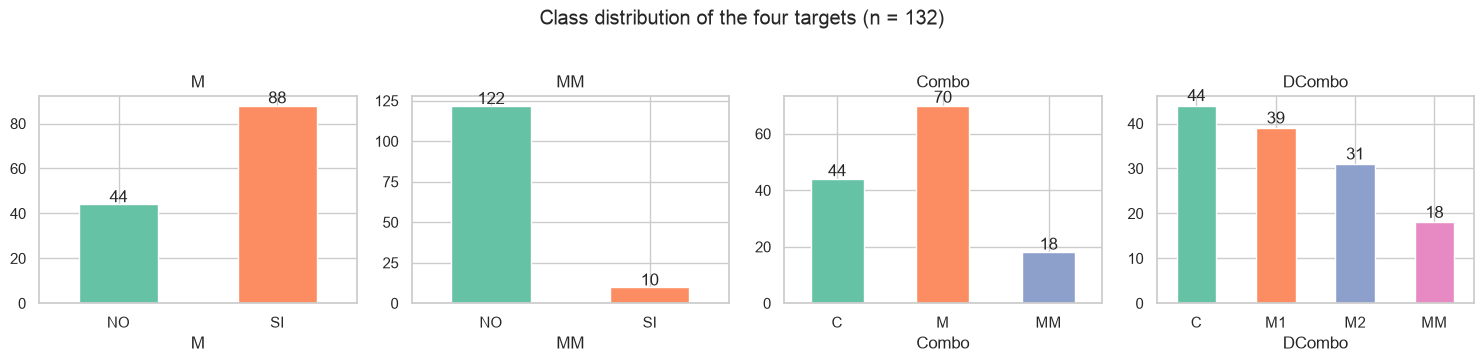

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, col in zip(axes, Y_train.columns):
    counts = Y_train[col].value_counts().sort_index()
    counts.plot.bar(ax=ax, color=sns.color_palette("Set2", len(counts)))
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=0)
    for i, v in enumerate(counts):
        ax.text(i, v + 1, str(v), ha="center")
plt.suptitle("Class distribution of the four targets (n = 132)", y=1.03)
plt.tight_layout()
plt.savefig(FIGURES / "01_targets.png", dpi=150, bbox_inches="tight")
plt.show()

**Class imbalance.** `MM` is the hardest task: only **10 positives out of 132** (7.6 %).
A model that always predicts `NO` would reach 92 % accuracy while being useless, so
accuracy alone is not a valid metric. We will use F1, balanced accuracy and stratified
cross-validation.

### 4.1 Are the four targets consistent with each other?

In [8]:
# Relationship between the targets
display(pd.crosstab(Y_train["Combo"], Y_train["MM"], margins=True))
display(pd.crosstab(Y_train["Combo"], Y_train["DCombo"]))

MM,NO,SI,All
Combo,,,
C,44,0,44
M,70,0,70
MM,8,10,18
All,122,10,132


DCombo,C,M1,M2,MM
Combo,,,,
C,44,0,0,0
M,0,39,31,0
MM,0,0,0,18


In [9]:
# Students labelled as myopia magna in Combo but NOT in the MM column
inconsistent = (Y_train["Combo"] == "MM") & (Y_train["MM"] == "NO")
print("Inconsistent rows:", inconsistent.sum())
pd.concat([X_train.loc[inconsistent, ["LA OD", "LA OS", "LA Media", "familiar miope"]],
           Y_train.loc[inconsistent]], axis=1)

Inconsistent rows: 8


,LA OD,LA OS,LA Media,familiar miope,M,MM,Combo,DCombo
55,26.25,26.63,26.44,"Padre, Madre",SI,NO,MM,MM
56,26.20,25.80,26.00,"Padre, Madre, Hermanos",SI,NO,MM,MM
84,26.74,26.96,26.85,"Padre, Hermanos",SI,NO,MM,MM
90,27.30,27.04,27.17,"Padre, Madre, Hermanos",SI,NO,MM,MM
99,26.17,26.00,26.09,"Padre, Madre, Hermanos",SI,NO,MM,MM
104,25.93,26.04,25.98,No,SI,NO,MM,MM
106,27.60,27.83,27.71,NaN,SI,NO,MM,MM
111,25.76,26.10,25.93,"Padre, Hermanos",SI,NO,MM,MM


**Label inconsistency found.** 8 students have `Combo = MM` but `MM = NO`.
`DCombo` agrees with `Combo` for them (`MM`), and `M` is `SI` for all of them.
The next cell compares their axial length (the main anatomical marker of myopia) with
the other groups.

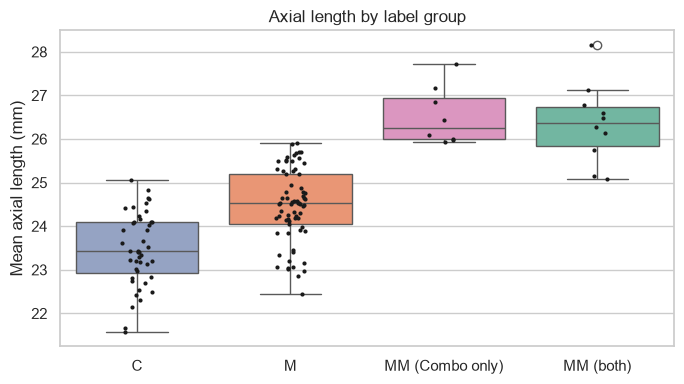

,count,mean,min,max
C,44.0,23.47,21.57,25.07
M,70.0,24.47,22.45,25.90
MM (Combo only),8.0,26.52,25.93,27.71
MM (both),10.0,26.35,25.08,28.16


In [10]:
groups = np.select(
    [Y_train["Combo"] == "C", Y_train["Combo"] == "M", inconsistent],
    ["C", "M", "MM (Combo only)"], default="MM (both)")

fig, ax = plt.subplots(figsize=(7, 4))
order = ["C", "M", "MM (Combo only)", "MM (both)"]
sns.boxplot(x=groups, y=X_train["LA Media"], order=order, ax=ax, palette="Set2", hue=groups, legend=False)
sns.stripplot(x=groups, y=X_train["LA Media"], order=order, ax=ax, color="k", size=3)
ax.set_xlabel("")
ax.set_ylabel("Mean axial length (mm)")
ax.set_title("Axial length by label group")
plt.tight_layout()
plt.savefig(FIGURES / "01_inconsistent_labels.png", dpi=150)
plt.show()

pd.Series(X_train["LA Media"].values, index=groups).groupby(level=0).describe()[["count", "mean", "min", "max"]]

The 8 "Combo-only" students have the same axial length as the confirmed myopia-magna
students (~26.5 mm) and much larger than simple myopes (~24.5 mm). This suggests they are
myopia-magna cases mislabelled in the `MM` column (or that both columns were built with
different criteria).

**Decision (to be confirmed by the team):** each task is trained on its own column as
provided, because the test set is most likely graded that way. We also keep this finding
for the report and test, as an extra experiment, the effect of correcting these 8 labels.

## 5. Data-quality issues in the features

### 5.1 `fototipo` and `Grupo fot`

In [11]:
pd.crosstab(X_train["fototipo"].fillna("NaN"), X_train["Grupo fot"].fillna("NaN"))

Grupo fot,E,L,NaN
fototipo,,,
E,36,0,0
Fototipo 1,9,0,0
Fototipo 2,5,0,0
Fototipo 3,31,0,0
Fototipo 4,23,0,3
Fototipo 5,2,0,0
L,0,2,0
NaN,0,0,21


`fototipo` should contain the skin phototype (1 to 5), but 38 rows contain `E` or `L`,
which are the values of `Grupo fot`. The two variables were mixed during data entry.
`Grupo fot` is almost constant (only 2 students are `L`), so it is nearly useless.
We will extract the numeric phototype (1-5) and treat `E`/`L` as missing.

### 5.2 Exam date

In [12]:
X_train["fecha"].value_counts()

fecha
2/24/20    17
2/18/20    14
2/12/20    13
2/10/20    13
2/17/20    12
2/11/20    11
2/19/20    11
2/26/20    10
2/25/20    10
3/2/20      7
3/4/20      7
2/26/97     4
3/3/20      2
3/10/20     1
Name: count, dtype: int64

All exams took place in February-March 2020, except 4 rows with the year `97`, clearly a typing
error. The exam date has no causal relation with myopia, so `fecha` will be dropped.

### 5.3 Derived (redundant) columns

In [13]:
# Several columns are sums or means of others. We check it numerically.
outdoor_sum = X_train[["hº deporte sem", "hº naturaleza sem", "hº ocio exteriores sem"]].sum(axis=1)  # missing parts count as 0
checks = {
    "horas exterior = deporte + naturaleza + ocio ext.":
        np.allclose(X_train["horas exterior sem"], outdoor_sum, equal_nan=True),
    "LA Media = (LA OD + LA OS) / 2":
        np.allclose(X_train["LA Media"], (X_train["LA OD"] + X_train["LA OS"]) / 2),
    "CUVAF-Total = OD-Total + OS-Total":
        np.allclose(X_train["CUVAF-Total"], X_train["OD-Total"] + X_train["OS-Total"]),
    "Suma Nasal = 2 * Promedio Nasal":
        np.allclose(X_train["Suma Nasal"], 2 * X_train["Promedio Nasal"]),
}
pd.Series(checks, name="holds")

horas exterior = deporte + naturaleza + ocio ext.    True
LA Media = (LA OD + LA OS) / 2                       True
CUVAF-Total = OD-Total + OS-Total                    True
Suma Nasal = 2 * Promedio Nasal                      True
Name: holds, dtype: bool

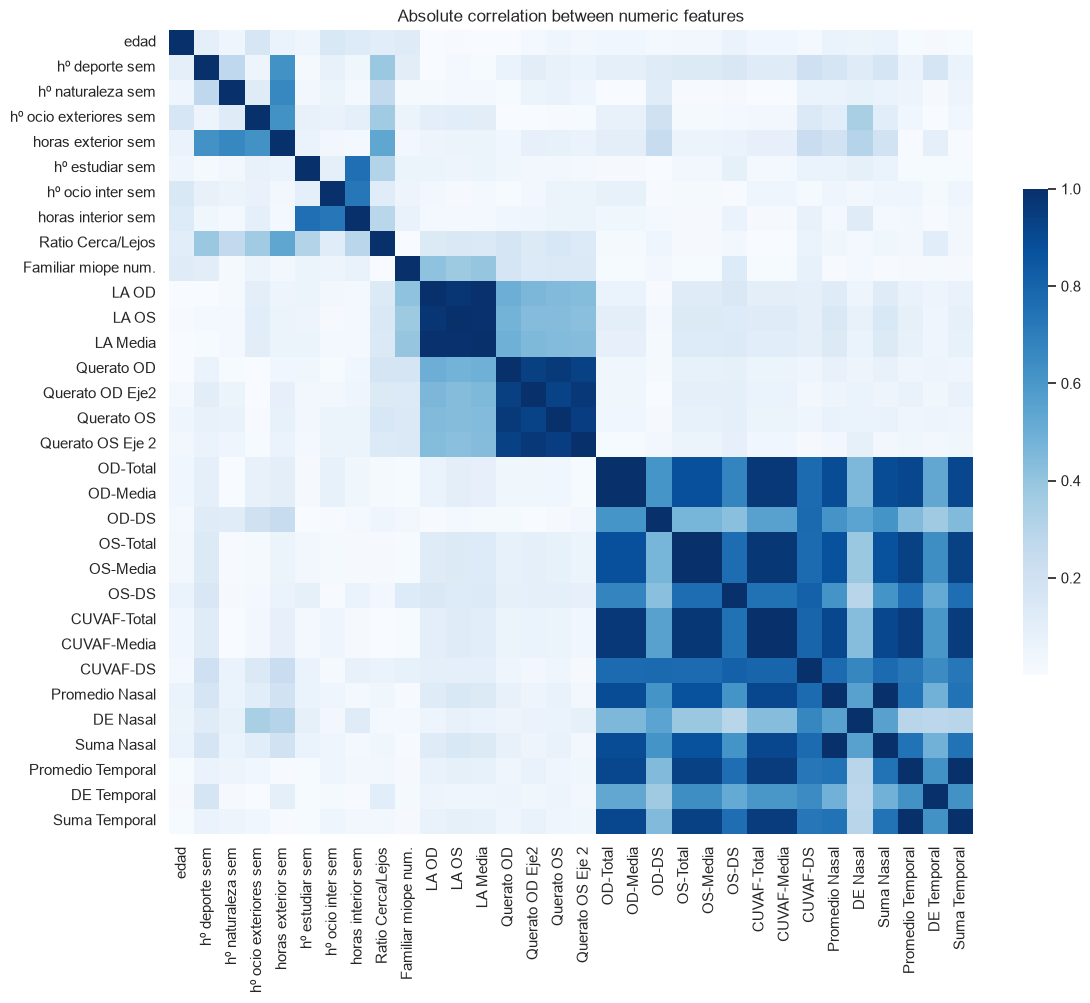

In [14]:
# Correlation between numeric features (absolute value)
corr = X_train[num_cols].drop(columns="hº act.cerca sem").corr().abs()
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="Blues", square=True, cbar_kws={"shrink": .6}, ax=ax)
ax.set_title("Absolute correlation between numeric features")
plt.tight_layout()
plt.savefig(FIGURES / "01_correlation.png", dpi=150)
plt.show()

Many features are exact combinations of others (right eye / left eye / mean / total).
Keeping all of them adds collinearity without new information, which hurts linear models
and makes feature importances hard to interpret. In feature engineering we will keep one
representative per group (e.g. the mean of both eyes).

### 5.4 Free-text and categorical columns

In [15]:
cat_cols = X_train.columns.difference(num_cols)
summary = pd.DataFrame({
    "n_unique": [pd.concat([X_train[c], X_test[c]]).nunique() for c in cat_cols],
    "examples": [pd.concat([X_train[c], X_test[c]]).dropna().unique()[:4].tolist() for c in cat_cols],
}, index=cat_cols).sort_values("n_unique", ascending=False)
summary

,n_unique,examples
origen antepasados (españa),95,"[Asturias, Navarra, Bizkaia, Navarra, Extremad..."
origen antepasados (extranjeros),18,"[España, Filipinas, No, Portugal]"
fecha,14,"[2/11/20, 2/17/20, 3/10/20, 2/26/20]"
familiar miope,10,"[Madre, Hermanos, No, Padre, Madre, Padre]"
familiar miope magno,8,"[Hermanos, No, No lo se, Padre]"
fototipo,7,"[Fototipo 3, Fototipo 4, E, Fototipo 5]"
Familiar MM SI/NO,3,"[Si, No, No lo se]"
disp.elec.antes dormir,3,"[A veces, Siempre, Nunca]"
pat. Ret. Miop magna,3,"[No, No lo se, Sí, en ambos ojos]"
Exterior Mucho,2,"[NO, SI]"


- `origen antepasados (españa)` has 95 different free-text values for 156 students: too
  sparse to be used directly. A simple derived flag (has foreign ancestors yes/no) is more
  useful.
- `familiar miope` lists which relatives are myopic (father, mother, siblings). It can be
  turned into binary columns (`father_myopic`, `mother_myopic`, `siblings_myopic`).
- The remaining columns are small yes/no or ordinal categories (`Nunca` < `A veces` < `Siempre`).

## 6. Which features are related to myopia?

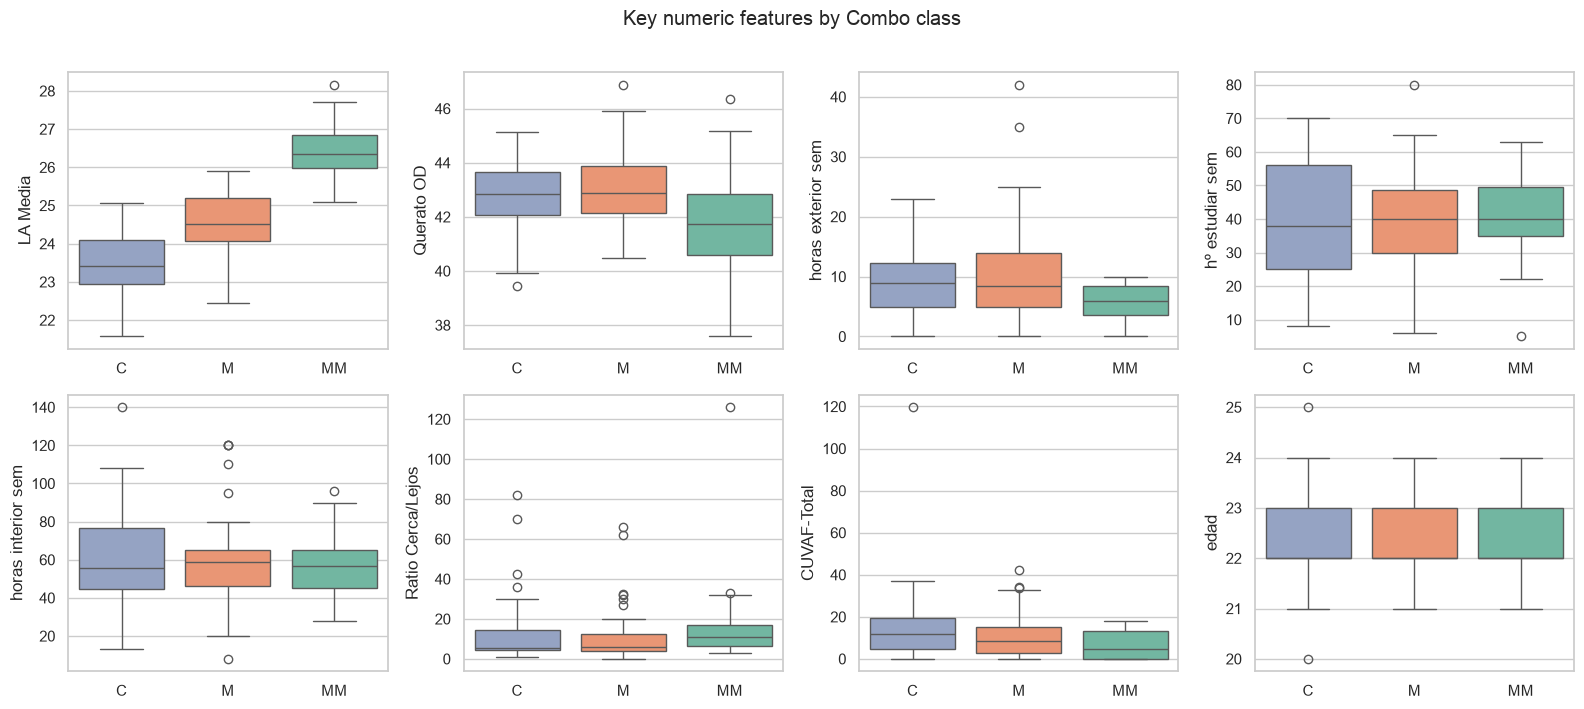

In [16]:
# Distribution of the main numeric features for myopic (SI) vs non-myopic (NO) students
key_vars = ["LA Media", "Querato OD", "horas exterior sem", "hº estudiar sem",
            "horas interior sem", "Ratio Cerca/Lejos", "CUVAF-Total", "edad"]
df = X_train.join(Y_train)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, var in zip(axes.ravel(), key_vars):
    sns.boxplot(data=df, x="Combo", y=var, order=["C", "M", "MM"], ax=ax,
                palette="Set2", hue="Combo", legend=False)
    ax.set_xlabel("")
plt.suptitle("Key numeric features by Combo class", y=1.01)
plt.tight_layout()
plt.savefig(FIGURES / "01_numeric_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
# Non-parametric test (Kruskal-Wallis) to rank numeric features by how well they separate C / M / MM
from scipy.stats import kruskal

rows = []
for var in num_cols.drop("hº act.cerca sem"):
    samples = [df.loc[df["Combo"] == g, var].dropna() for g in ["C", "M", "MM"]]
    stat, p = kruskal(*samples)
    rows.append((var, stat, p))
ranking = pd.DataFrame(rows, columns=["feature", "H", "p_value"]).sort_values("p_value")
ranking.head(12)

,feature,H,p_value
11,LA OS,65.83,5.07e-15
12,LA Media,64.70,8.93e-15
10,LA OD,62.98,2.11e-14
9,Familiar miope num.,16.54,2.56e-04
1,hº deporte sem,12.89,1.59e-03
20,OS-Total,8.82,1.22e-02
21,OS-Media,8.82,1.22e-02
13,Querato OD,8.40,1.50e-02
28,Suma Nasal,7.43,2.44e-02
26,Promedio Nasal,7.43,2.44e-02


Axial length (`LA`) is by far the strongest predictor (p ~ 1e-14), followed at a long
distance by the number of myopic parents and the weekly hours of sport: it grows from ~23.5 mm (controls)
to ~24.5 mm (myopia) and ~26.4 mm (myopia magna). This is consistent with the medical
literature: myopia is mainly caused by an elongated eyeball.

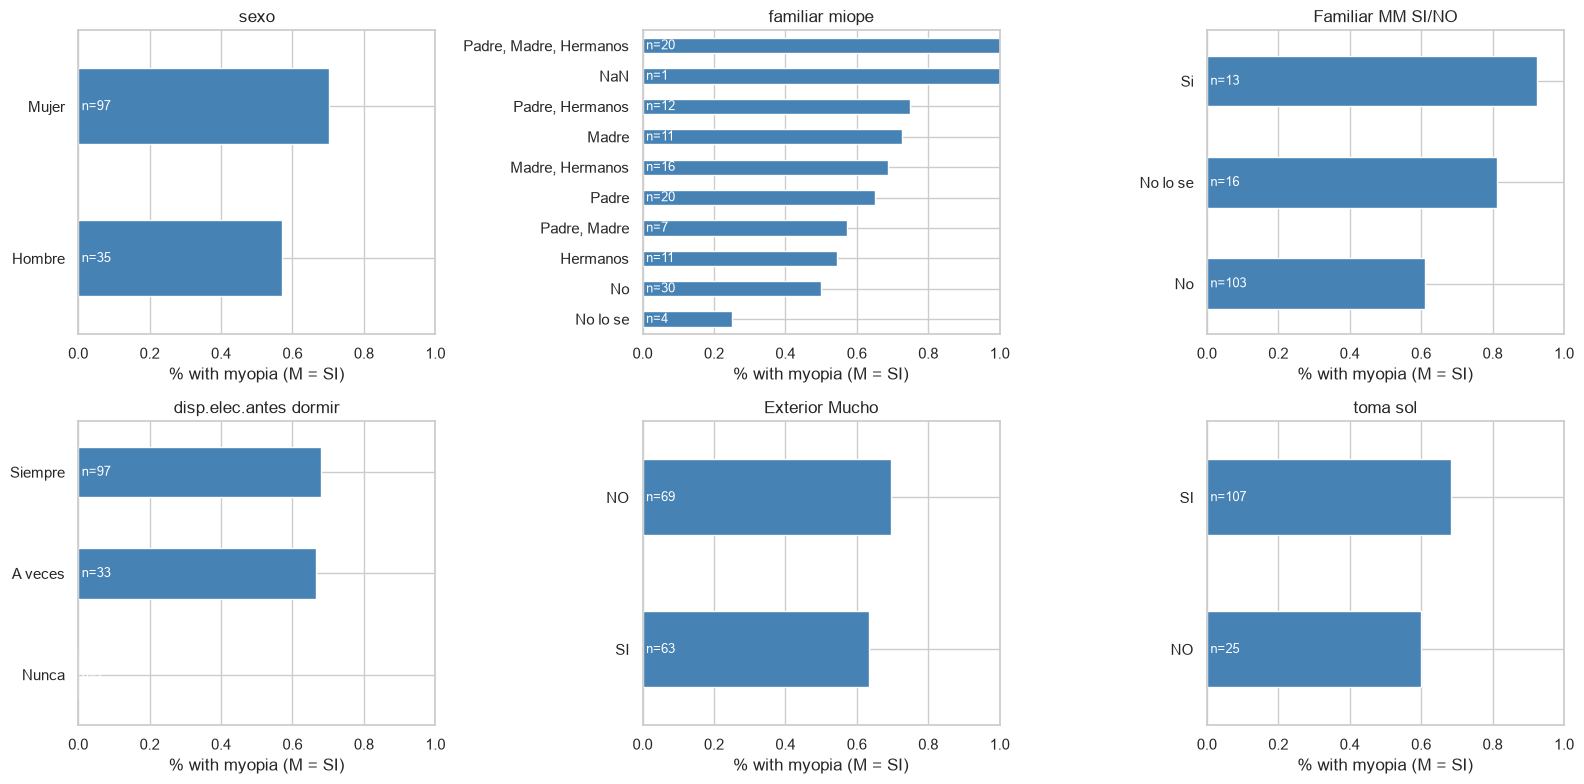

In [18]:
# Proportion of myopic students for each value of some categorical features
cat_vars = ["sexo", "familiar miope", "Familiar MM SI/NO", "disp.elec.antes dormir", "Exterior Mucho", "toma sol"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, var in zip(axes.ravel(), cat_vars):
    prop = pd.crosstab(df[var].fillna("NaN"), df["M"], normalize="index")["SI"]
    n = df[var].fillna("NaN").value_counts()
    prop.sort_values().plot.barh(ax=ax, color="steelblue")
    ax.set_xlim(0, 1)
    ax.set_xlabel("% with myopia (M = SI)")
    ax.set_ylabel("")
    ax.set_title(var)
    for i, k in enumerate(prop.sort_values().index):
        ax.text(0.01, i, f"n={n[k]}", va="center", color="white", fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES / "01_categorical_vs_M.png", dpi=150)
plt.show()

## 7. Do train and test come from the same distribution?

If the test students were very different from the training students, the validation score
would be an optimistic estimate of the test score.

In [19]:
from scipy.stats import ks_2samp

# Kolmogorov-Smirnov test on each numeric column (small p-value = different distributions)
shift = []
for var in num_cols.drop("hº act.cerca sem"):
    stat, p = ks_2samp(X_train[var].dropna(), X_test[var].dropna())
    shift.append((var, round(stat, 2), round(p, 3)))
shift = pd.DataFrame(shift, columns=["feature", "KS", "p_value"]).sort_values("p_value")
shift.head(8)

,feature,KS,p_value
9,Familiar miope num.,0.29,0.06
27,DE Nasal,0.23,0.20
7,horas interior sem,0.23,0.21
3,hº ocio exteriores sem,0.21,0.27
5,hº estudiar sem,0.21,0.28
2,hº naturaleza sem,0.22,0.29
16,Querato OS Eje 2,0.19,0.39
25,CUVAF-DS,0.19,0.39


With only 24 test students the test has little power, but no feature shows a strong shift,
so train and test can be treated as samples from the same population.

## 8. Summary of findings and decisions for notebook 02

| # | Finding | Action |
|---|---|---|
| 1 | Same columns; 3 numeric columns with different dtype (int/float) | Cast all numeric columns to float |
| 2 | `hº act.cerca sem` 100 % empty | Drop |
| 3 | `fecha` irrelevant and with typos | Drop |
| 4 | `fototipo` mixed with `Grupo fot` values (`E`, `L`) | Keep numeric phototype 1-5, `E`/`L` → missing, impute |
| 5 | `Grupo fot` almost constant | Drop |
| 6 | Many redundant columns (eye OD/OS/mean/total, outdoor sum) | Keep one representative per group |
| 7 | Free-text ancestry (95 values) | Binary flag "foreign ancestors" |
| 8 | `familiar miope` lists relatives | One binary column per relative |
| 9 | 8 rows with `Combo = MM` but `MM = NO` | Train each task on its own column; test correction as extra experiment |
| 10 | Strong imbalance (`MM`: 10 / 132) | Stratified CV, F1 / balanced accuracy, class weights |
| 11 | Axial length is the dominant predictor | Expect it at the top of feature importances |